# Building Age Classification — Improved Model (Notebook 7)

This notebook improves on **6-Combined_Model** using what its diagnostic report showed:

| Finding from the report | Fix in this notebook |
|---|---|
| Transfer blend gave 91 % weight to the weakest part (A) at n = 5 → lost to the prototype baseline (0.517 vs 0.562) | **Ensemble of A + B + prototype, weights tuned per n** on separate tuning draws |
| Year-to-year change features had negative importance | **Dropped** (33 features) |
| Year regressor transferred badly (zero-shot 0.39) | **Removed** from the transfer step |
| Main error: Class 1 ↔ Class 2 (33 % of C1 predicted C2) | **Spatial context**: neighbourhood features (90 m and 300 m) + **spatial smoothing** of predictions |

It starts from `outputs/features_cache.joblib`, so the slow Steps 1–5 of Notebook 6 are **not** repeated.
Results are written to a new folder **`outputs_v2/`** — your previous results stay untouched for comparison.

> **Run order:** *Run → Run All Cells*. The slowest cell is Step 3 (3 feature sets × 5 folds). `[*]` = still working.

---
## Step 0 — Setup and configuration

In [9]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy import ndimage
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, confusion_matrix, classification_report
warnings.filterwarnings('ignore')

# ══════════════════════════════ CONFIG ══════════════════════════════════════
SEED        = 42
CLASSES     = [1, 2, 3, 4]
IN_DIR      = Path('outputs')            # where Notebook 6 saved its files
OUT_DIR     = Path('outputs_v2'); OUT_DIR.mkdir(exist_ok=True)

DROP_GROUPS = ['year-to-year change']    # feature groups to remove (negative importance in the report)
NB_RADII    = [3, 10]                    # neighbourhood radius in pixels: 3 = 90 m, 10 = 300 m
NB_TOP      = 30                         # how many top-ranked features get neighbourhood versions

N_FOLDS, BLOCK_PX = 5, 50                # same spatial CV as Notebook 6 (1.5 km blocks)
SHOTS       = [5, 25, 50, 100, 200]
N_TRIALS    = 10                         # reporting draws per n (same seeds as Notebook 6 -> comparable)
N_TUNE      = 5                          # separate tuning draws per n (different seeds)
C_GRID      = [0.02, 0.05, 0.2, 1.0]     # regularisation strengths tried for the local model B
SMOOTH_RADIUS, SMOOTH_ALPHA = 2, 0.5     # prediction smoothing: 5x5 pixel window, 50 % neighbours

HGB_KW = dict(learning_rate=0.08, max_iter=400, max_leaf_nodes=48, min_samples_leaf=40,
              l2_regularization=1.0, early_stopping=True, validation_fraction=0.1, n_iter_no_change=30)
# ════════════════════════════════════════════════════════════════════════════
print('Reading from', IN_DIR.resolve(), '| writing to', OUT_DIR.resolve())

Reading from /home/participant-c3/Building_Age_Classification/outputs | writing to /home/participant-c3/Building_Age_Classification/outputs_v2


---
## Step 1 — Load the saved features from Notebook 6

`features_cache.joblib` holds, for both cities, the 248 features (190 of mine + 58 from Notebook 3) and the pixel
table (pixel position, coverage, construction year, class). The held-out feature ranking from Step 9b is used to
decide which features get neighbourhood versions.

In [10]:
F_mad, F_ams, pix_mad, pix_ams = joblib.load(IN_DIR / 'features_cache.joblib')
F_mad, F_ams = F_mad.reset_index(drop=True), F_ams.reset_index(drop=True)
pix_mad, pix_ams = pix_mad.reset_index(drop=True), pix_ams.reset_index(drop=True)

def feature_group(c):
    if c.startswith('nb'): return 'neighbourhood (new)'
    if c.startswith('org_'): return 'Notebook 3 (org_)'
    if 'brk' in c: return 'change-point'
    if c.endswith(('_dmax', '_dmax_year', '_dstd')): return 'year-to-year change'
    if '_era' in c: return 'decade means'
    if c.endswith(('_early', '_late', '_late_minus_early')): return 'early vs late'
    if c.endswith('_slope'): return 'trend'
    if c == 'coverage': return 'coverage'
    return 'level (mean/std/median)'

ranking = None
for fname in ['feature_ranking_heldout.csv', 'feature_importance.csv']:
    if (IN_DIR / fname).exists():
        ranking = pd.read_csv(IN_DIR / fname, index_col=0).iloc[:, 0].sort_values(ascending=False)
        print('Feature ranking from', fname); break

lab_mad = pix_mad['age_class'].notna().to_numpy()
lab_ams = pix_ams['age_class'].notna().to_numpy()
y_mad = pix_mad.loc[lab_mad, 'age_class'].to_numpy(int)
y_ams = pix_ams.loc[lab_ams, 'age_class'].to_numpy(int)
print(f'Madrid {F_mad.shape}, labelled {lab_mad.sum():,} | Amsterdam {F_ams.shape}, labelled {lab_ams.sum():,}')

Feature ranking from feature_ranking_heldout.csv
Madrid (76263, 248), labelled 76,263 | Amsterdam (25992, 248), labelled 25,992


---
## Step 2 — Spatial context: neighbourhood features

Buildings of the same era cluster (historic centres, post-war estates). So for each pixel we add the **average of
the top-ranked features over its neighbourhood** — a 7×7 window (≈ 90 m) and a 21×21 window (≈ 300 m) — plus the
**building density** around it (as a percentile within its own city, so it is comparable between cities).

Only features are averaged — **never labels** — so there is no leakage. The pixel grid comes from `px_key`/`py_key`
(30 m units).

In [11]:
class Grid:
    # Places per-pixel values on the 30 m grid so neighbourhood averages can be computed with image filters.
    def __init__(self, pix):
        px, py = pix['px_key'].to_numpy(int), pix['py_key'].to_numpy(int)
        self.gx, self.gy = px - px.min(), py - py.min()
        self.shape = (self.gy.max() + 1, self.gx.max() + 1)
        self.mask = np.zeros(self.shape, 'float32'); self.mask[self.gy, self.gx] = 1
        self._cnt = {}
    def count(self, r):
        if r not in self._cnt:
            self._cnt[r] = ndimage.uniform_filter(self.mask, 2 * r + 1, mode='constant')[self.gy, self.gx]
        return self._cnt[r]
    def mean(self, values, r):
        g = np.zeros(self.shape, 'float32'); g[self.gy, self.gx] = values
        return ndimage.uniform_filter(g, 2 * r + 1, mode='constant')[self.gy, self.gx] / np.maximum(self.count(r), 1e-6)

KEEP = [c for c in F_mad.columns if feature_group(c) not in DROP_GROUPS]
nb_source = [c for c in (ranking.index if ranking is not None else KEEP) if c in KEEP][:NB_TOP]
print(f'Kept {len(KEEP)} of {F_mad.shape[1]} features (dropped groups: {DROP_GROUPS})')
print(f'Neighbourhood versions for the top {len(nb_source)}:', nb_source[:8], '...')

def neighbourhood_features(F, pix):
    grid, out = Grid(pix), {}
    for r in NB_RADII:
        out[f'nb{r}_density'] = pd.Series(grid.count(r)).rank(pct=True).to_numpy()
        for c in nb_source:
            out[f'nb{r}_{c}'] = grid.mean(F[c].to_numpy('float32'), r)
    return pd.DataFrame(out).astype('float32')

t = time.time()
NB_mad = neighbourhood_features(F_mad, pix_mad)
NB_ams = neighbourhood_features(F_ams, pix_ams)
F_mad = pd.concat([F_mad, NB_mad], axis=1)
F_ams = pd.concat([F_ams, NB_ams], axis=1)
NB_COLS = list(NB_mad.columns)
print(f'Added {len(NB_COLS)} neighbourhood features in {time.time()-t:.0f}s')

CANDIDATES = {
    'previous (all 248)':          [c for c in F_mad.columns if not c.startswith('nb')],
    'drop year-to-year':           KEEP,
    'drop + neighbourhood':        KEEP + NB_COLS,
}
for k, v in CANDIDATES.items():
    print(f'  {k:24s}: {len(v)} features')

Kept 215 of 248 features (dropped groups: ['year-to-year change'])
Neighbourhood versions for the top 30: ['Red_era2', 'UI_era1', 'NIR_era1', 'Red_std', 'NDVI_era2', 'BSI_era1', 'coverage', 'MNDWI_brk_year'] ...
Added 62 neighbourhood features in 1s
  previous (all 248)      : 248 features
  drop year-to-year       : 215 features
  drop + neighbourhood    : 277 features


---
## Step 3 — Madrid: compare the three feature sets (same spatial folds as Notebook 6)

Model: gradient boosting with class-imbalance correction (the winner in Notebook 6).
For each fold we report macro-F1 **raw** and **smoothed** (each pixel's probabilities mixed 50/50 with the
average of its 5×5 neighbourhood). Smoothing only uses pixels of the **same test fold**, so no training labels leak in.

In [12]:
class BalancedHGB:
    def __init__(self, seed=SEED):
        self.m = HistGradientBoostingClassifier(random_state=seed, **HGB_KW)
    def fit(self, X, y):
        self.m.fit(X, y)
        self.prior = np.array([(y == c).mean() for c in CLASSES]) + 1e-9
        return self
    def predict_proba(self, X):
        P = self.m.predict_proba(X) / self.prior
        return P / P.sum(1, keepdims=True)

def smooth(P, grid, r=SMOOTH_RADIUS, alpha=SMOOTH_ALPHA):
    nb = np.column_stack([grid.mean(P[:, k].astype('float32'), r) for k in range(P.shape[1])])
    out = (1 - alpha) * P + alpha * nb
    return out / out.sum(1, keepdims=True)

def macro_f1(y, P):
    return f1_score(y, np.array(CLASSES)[P.argmax(1)], average='macro')

pix_mad_lab = pix_mad[lab_mad].reset_index(drop=True)
groups = (pix_mad_lab['px_key'].to_numpy() // BLOCK_PX) * 100_000 + pix_mad_lab['py_key'].to_numpy() // BLOCK_PX
splits = list(StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(y_mad)), y_mad, groups))

madrid = {}
t = time.time()
for name, cols in CANDIDATES.items():
    X = F_mad.loc[lab_mad, cols].to_numpy('float32')
    raw, sm, oof = [], [], np.zeros((len(y_mad), 4))
    for f, (tr, va) in enumerate(splits, 1):
        P = BalancedHGB().fit(X[tr], y_mad[tr]).predict_proba(X[va])
        Ps = smooth(P, Grid(pix_mad_lab.iloc[va]))
        raw.append(macro_f1(y_mad[va], P)); sm.append(macro_f1(y_mad[va], Ps)); oof[va] = Ps
    madrid[name] = {'raw': raw, 'smoothed': sm, 'oof': oof}
    print(f'{name:24s}: raw {np.mean(raw):.4f} ± {np.std(raw):.4f} | smoothed {np.mean(sm):.4f} ± {np.std(sm):.4f}'
          f'  ({time.time()-t:.0f}s)')
print('\nNotebook 6 result on the same folds: HGB classifier 0.6222 ± 0.0234')

previous (all 248)      : raw 0.6222 ± 0.0234 | smoothed 0.6443 ± 0.0257  (123s)
drop year-to-year       : raw 0.6190 ± 0.0226 | smoothed 0.6417 ± 0.0253  (233s)
drop + neighbourhood    : raw 0.6500 ± 0.0284 | smoothed 0.6565 ± 0.0297  (381s)

Notebook 6 result on the same folds: HGB classifier 0.6222 ± 0.0234


---
## Step 4 — Transfer to Amsterdam with a tuned ensemble

For every feature set: train Stage 1 on all of Madrid, then for each n:

- **A** – recalibrated Stage 1: logistic regression on the 4 Stage-1 log-probabilities
- **B** – local model: regularised logistic regression on all (Amsterdam-standardised) features + Stage-1 log-probabilities
- **P** – prototype (Notebook 4's method): nearest class mean, turned into probabilities
- **Ensemble** = wA·A + wP·P + (1 − wA − wP)·B, optionally spatially smoothed

**Tuning without cheating:** the weights, B's regularisation `C` and smoothing on/off are chosen per n on
`N_TUNE` *separate* random draws (different seeds). They are then fixed, and the score is reported on the
`N_TRIALS` reporting draws — the very same draws Notebook 6 used, so the numbers are directly comparable.
(The organisers' held-out test set gives the final, fully independent score.)

In [13]:
W_GRID = [(a, p) for a in (0, 0.2, 0.4) for p in (0, 0.2, 0.4, 0.6) if a + p <= 1]
grid_ams = Grid(pix_ams[lab_ams].reset_index(drop=True))

def sample_support(y, n, rng):
    return np.concatenate([rng.choice(np.where(y == c)[0], size=min(n, (y == c).sum()), replace=False)
                           for c in CLASSES])

def proto_proba(Z_sup, y_sup, Z):
    P = np.stack([Z_sup[y_sup == c].mean(0) for c in CLASSES])
    d = np.sqrt(np.maximum((Z ** 2).sum(1)[:, None] - 2 * Z @ P.T + (P ** 2).sum(1)[None], 0))
    e = np.exp(-(d - d.min(1, keepdims=True)))
    return e / e.sum(1, keepdims=True)

def parts(sup, L, Z, C):
    # probabilities of A, B, P for ALL Amsterdam pixels (support pixels included, needed for smoothing)
    A = LogisticRegression(C=1.0, max_iter=3000, random_state=SEED).fit(L[sup], y_ams[sup])
    ZL = np.hstack([Z, L])
    B = LogisticRegression(C=C, max_iter=3000, random_state=SEED, class_weight='balanced').fit(ZL[sup], y_ams[sup])
    return A.predict_proba(L), B.predict_proba(ZL), proto_proba(Z[sup], y_ams[sup], Z)

def combine(pa, pb, pp, wA, wP, sm):
    P = wA * pa + wP * pp + (1 - wA - wP) * pb
    return smooth(P, grid_ams) if sm else P

def evaluate_transfer(name, cols):
    t = time.time()
    Xm, Xa = F_mad.loc[lab_mad, cols].to_numpy('float32'), F_ams.loc[lab_ams, cols].to_numpy('float32')
    s1 = BalancedHGB().fit(Xm, y_mad)
    L  = np.log(np.clip(s1.predict_proba(Xa), 1e-6, 1))
    Z  = StandardScaler().fit_transform(Xa)
    zero = macro_f1(y_ams, L)
    chosen, rows = {}, []
    for n in SHOTS:
        # ── tuning on separate draws ──
        scores = {}
        for trial in range(N_TUNE):
            rng = np.random.default_rng(SEED + 77_777 + 1000 * n + trial)
            sup = sample_support(y_ams, n, rng); q = np.setdiff1d(np.arange(len(y_ams)), sup)
            for C in C_GRID:
                pa, pb, pp = parts(sup, L, Z, C)
                for wA, wP in W_GRID:
                    for sm in (False, True):
                        scores.setdefault((C, wA, wP, sm), []).append(
                            macro_f1(y_ams[q], combine(pa, pb, pp, wA, wP, sm)[q]))
        best = max(scores, key=lambda k: np.mean(scores[k]))
        chosen[n] = dict(zip(['C', 'wA', 'wP', 'smooth'], best))
        # ── reporting on Notebook 6's draws ──
        C, wA, wP, sm = best
        for trial in range(N_TRIALS):
            rng = np.random.default_rng(SEED + 1000 * n + trial)
            sup = sample_support(y_ams, n, rng); q = np.setdiff1d(np.arange(len(y_ams)), sup)
            pa, pb, pp = parts(sup, L, Z, C)
            for method, P in [('ensemble (tuned)', combine(pa, pb, pp, wA, wP, sm)),
                              ('A only', pa), ('B only', pb), ('prototype', pp)]:
                rows.append({'features': name, 'n': n, 'trial': trial, 'method': method,
                             'f1': macro_f1(y_ams[q], P[q])})
    print(f'{name:24s}: zero-shot {zero:.4f} | done in {time.time()-t:.0f}s')
    return pd.DataFrame(rows), chosen, zero, s1

transfer, tuned, zeroshot, stage1s = [], {}, {}, {}
for name, cols in CANDIDATES.items():
    df, ch, z, s1 = evaluate_transfer(name, cols)
    transfer.append(df); tuned[name], zeroshot[name], stage1s[name] = ch, z, s1
transfer = pd.concat(transfer, ignore_index=True)
transfer.to_csv(OUT_DIR / 'amsterdam_transfer_all_trials.csv', index=False)

ens = transfer[transfer['method'] == 'ensemble (tuned)'].groupby(['features', 'n'])['f1'].mean().unstack('n')
ens['average (prize 1)'] = ens[SHOTS].mean(1)
print('\nAmsterdam macro-F1, tuned ensemble (Notebook 6 blend: 0.517 / 0.628 / 0.650 / 0.668 / 0.680, avg 0.629)')
ens.round(4)

previous (all 248)      : zero-shot 0.4946 | done in 92s
drop year-to-year       : zero-shot 0.4549 | done in 94s
drop + neighbourhood    : zero-shot 0.5589 | done in 101s

Amsterdam macro-F1, tuned ensemble (Notebook 6 blend: 0.517 / 0.628 / 0.650 / 0.668 / 0.680, avg 0.629)


n,5,25,50,100,200,average (prize 1)
features,,,,,,
drop + neighbourhood,0.6055,0.6852,0.7118,0.7329,0.7388,0.6948
drop year-to-year,0.5840,0.6612,0.6868,0.7075,0.7156,0.6710
previous (all 248),0.5744,0.6654,0.6866,0.7083,0.7145,0.6698


---
## Step 5 — Summary: which feature set wins?

The winner is chosen by the **average Amsterdam F1** (prize 1), which also reflects the low-data case.

In [14]:
summary = pd.DataFrame({
    'Madrid raw':       {k: np.mean(v['raw']) for k, v in madrid.items()},
    'Madrid smoothed':  {k: np.mean(v['smoothed']) for k, v in madrid.items()},
    'zero-shot Ams':    zeroshot,
    'Ams n=5':          ens[5], 'Ams n=25 (prize 3)': ens[25], 'Ams n=200': ens[200],
    'Ams average (prize 1)': ens['average (prize 1)'],
}).round(4)
summary.loc['Notebook 6 (reference)'] = [0.6222, np.nan, 0.4946, 0.5172, 0.6276, 0.6802, 0.6286]
summary.to_csv(OUT_DIR / 'feature_set_comparison.csv')
display(summary)

BEST = summary.drop('Notebook 6 (reference)')['Ams average (prize 1)'].idxmax()
print(f'\nBest feature set: {BEST}')
print('Tuned settings per n:')
for n, s in tuned[BEST].items():
    print(f'  n={n:3d}: weight A={s["wA"]}, prototype={s["wP"]}, B={1 - s["wA"] - s["wP"]:.1f}, '
          f'C={s["C"]}, smoothing={"on" if s["smooth"] else "off"}')

meth = transfer[transfer['features'] == BEST].groupby(['method', 'n'])['f1'].agg(['mean', 'std']).unstack('n')
print('\nAll methods for the best feature set:'); display(meth.round(4))

,Madrid raw,Madrid smoothed,zero-shot Ams,Ams n=5,Ams n=25 (prize 3),Ams n=200,Ams average (prize 1)
drop + neighbourhood,0.6500,0.6565,0.5589,0.6055,0.6852,0.7388,0.6948
drop year-to-year,0.6190,0.6417,0.4549,0.5840,0.6612,0.7156,0.6710
previous (all 248),0.6222,0.6443,0.4946,0.5744,0.6654,0.7145,0.6698
Notebook 6 (reference),0.6222,NaN,0.4946,0.5172,0.6276,0.6802,0.6286



Best feature set: drop + neighbourhood
Tuned settings per n:
  n=  5: weight A=0.4, prototype=0, B=0.6, C=0.02, smoothing=on
  n= 25: weight A=0.4, prototype=0, B=0.6, C=0.05, smoothing=on
  n= 50: weight A=0.4, prototype=0, B=0.6, C=0.02, smoothing=on
  n=100: weight A=0, prototype=0, B=1.0, C=0.02, smoothing=on
  n=200: weight A=0, prototype=0, B=1.0, C=0.02, smoothing=on

All methods for the best feature set:


mean                                     std          \
n                    5       25      50      100     200     5       25    
method                                                                     
A only            0.5395  0.6253  0.6382  0.6443  0.6468  0.0723  0.0175   
B only            0.5693  0.6676  0.7018  0.7251  0.7325  0.0451  0.0232   
ensemble (tuned)  0.6055  0.6852  0.7118  0.7329  0.7388  0.0627  0.0207   
prototype         0.5528  0.6109  0.6164  0.6199  0.6177  0.0233  0.0107   

                                          
n                    50      100     200  
method                                    
A only            0.0093  0.0064  0.0052  
B only            0.0188  0.0062  0.0042  
ensemble (tuned)  0.0122  0.0059  0.0046  
prototype         0.0111  0.0060  0.0039

---
## Step 6 — Final results for the slides (Madrid confusion, table, F1 vs log2(n) plot)

Madrid (drop + neighbourhood, smoothed): 0.6565 ± 0.0297
              precision    recall  f1-score   support

           1      0.596     0.573     0.584     13794
           2      0.659     0.709     0.683     27152
           3      0.662     0.640     0.651     18672
           4      0.737     0.696     0.716     16645

    accuracy                          0.665     76263
   macro avg      0.663     0.655     0.658     76263
weighted avg      0.665     0.665     0.664     76263



,Model,Macro F1 (mean),Std
0,"Madrid (Stage 1, spatial CV, smoothed)",0.6565,0.0297
1,"Amsterdam, n = 5/class",0.6055,0.0627
2,"Amsterdam, n = 25/class",0.6852,0.0207
3,"Amsterdam, n = 50/class",0.7118,0.0122
4,"Amsterdam, n = 100/class",0.7329,0.0059
5,"Amsterdam, n = 200/class",0.7388,0.0046


Prize 1 average: 0.6948 | Prize 2 peak: 0.7388 | Prize 3 (n=25): 0.6852


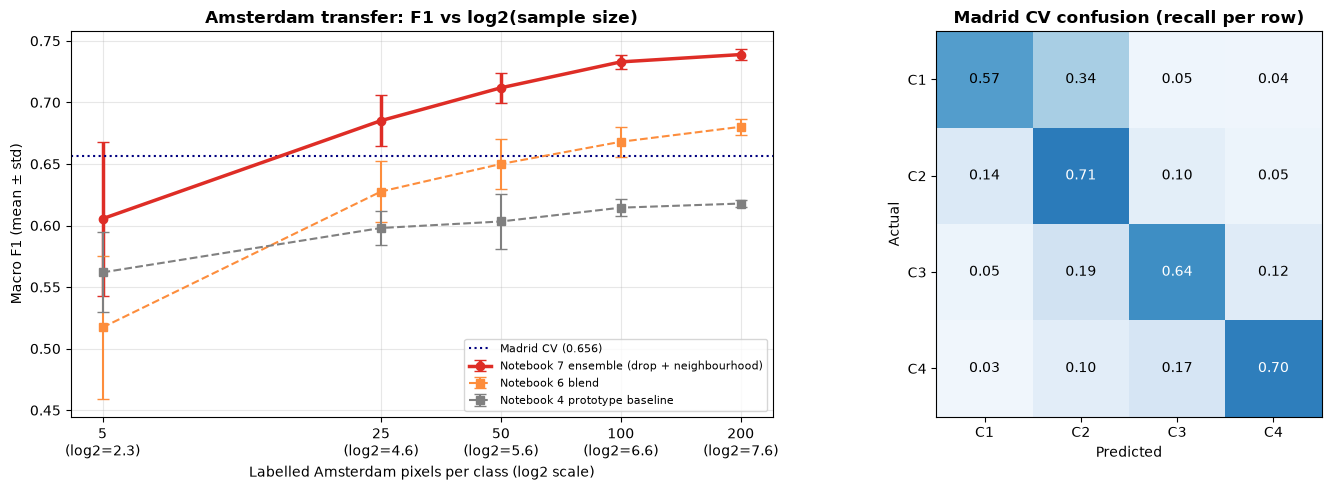

In [15]:
use_smooth_madrid = np.mean(madrid[BEST]['smoothed']) > np.mean(madrid[BEST]['raw'])
key = 'smoothed' if use_smooth_madrid else 'raw'
MAD_MEAN, MAD_STD = np.mean(madrid[BEST][key]), np.std(madrid[BEST][key])
oof_pred = np.array(CLASSES)[madrid[BEST]['oof'].argmax(1)]
print(f'Madrid ({BEST}, {key}): {MAD_MEAN:.4f} ± {MAD_STD:.4f}')
if key == 'raw':
    print('(confusion matrix below is from smoothed predictions)')
print(classification_report(y_mad, oof_pred, digits=3))
cm = confusion_matrix(y_mad, oof_pred, labels=CLASSES, normalize='true')
pd.DataFrame(cm, index=[f'true C{c}' for c in CLASSES], columns=[f'pred C{c}' for c in CLASSES]
             ).round(3).to_csv(OUT_DIR / 'madrid_cv_confusion_proportions.csv')

final = transfer[(transfer['features'] == BEST) & (transfer['method'] == 'ensemble (tuned)')
                 ].groupby('n')['f1'].agg(['mean', 'std'])
table = pd.DataFrame({'Model': [f'Madrid (Stage 1, spatial CV, {key})'] + [f'Amsterdam, n = {n}/class' for n in final.index],
                      'Macro F1 (mean)': [MAD_MEAN] + final['mean'].tolist(),
                      'Std': [MAD_STD] + final['std'].tolist()}).round(4)
table.to_csv(OUT_DIR / 'results_table.csv', index=False)
display(table)
print(f"Prize 1 average: {final['mean'].mean():.4f} | Prize 2 peak: {final['mean'].max():.4f} | "
      f"Prize 3 (n=25): {final.loc[25, 'mean']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.errorbar(np.log2(final.index), final['mean'], yerr=final['std'], fmt='o-', color='#de2d26', lw=2.5,
            capsize=4, label=f'Notebook 7 ensemble ({BEST})')
prev_path = IN_DIR / 'amsterdam_transfer_all_trials.csv'
if prev_path.exists():
    prev = pd.read_csv(prev_path)
    for method, col, lab in [('blend (final)', '#fd8d3c', 'Notebook 6 blend'),
                             ('prototype (NB4 baseline)', 'grey', 'Notebook 4 prototype baseline')]:
        s = prev[prev['method'] == method].groupby('n')['f1'].agg(['mean', 'std'])
        ax.errorbar(np.log2(s.index), s['mean'], yerr=s['std'], fmt='s--', color=col, capsize=4, label=lab)
ax.axhline(MAD_MEAN, color='navy', ls=':', label=f'Madrid CV ({MAD_MEAN:.3f})')
ax.set_xticks(np.log2(SHOTS), [f'{n}\n(log2={np.log2(n):.1f})' for n in SHOTS])
ax.set_xlabel('Labelled Amsterdam pixels per class (log2 scale)'); ax.set_ylabel('Macro F1 (mean ± std)')
ax.set_title('Amsterdam transfer: F1 vs log2(sample size)', fontweight='bold'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax = axes[1]
ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', color='white' if cm[i, j] > 0.6 else 'black')
ax.set_xticks(range(4), [f'C{c}' for c in CLASSES]); ax.set_yticks(range(4), [f'C{c}' for c in CLASSES])
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Madrid CV confusion (recall per row)', fontweight='bold')
plt.tight_layout(); plt.savefig(OUT_DIR / 'final_results.png', dpi=150); plt.show()

---
## Step 7 — Save the deliverables

- `stage1_madrid_model.joblib` — Stage 1 model (deliverable 1)
- `amsterdam_model_n{5,25,50,100,200}.joblib` — the five adapted Amsterdam models
- `adapt_to_amsterdam(n)` — the runnable, parameterised transfer code (deliverable 2), with a fixed seed.
  For an `n` that was not tuned it uses the settings of the nearest tuned n (on a log scale).

In [17]:
FEATURES = CANDIDATES[BEST]
X_ams_final = F_ams.loc[lab_ams, FEATURES].to_numpy('float32')
stage1 = stage1s[BEST]
joblib.dump({'model': stage1, 'features': FEATURES, 'feature_set': BEST, 'tuned': tuned[BEST],
             'config': {'SEED': SEED, 'NB_RADII': NB_RADII, 'NB_SOURCE': nb_source, 'DROP_GROUPS': DROP_GROUPS,
                        'SMOOTH_RADIUS': SMOOTH_RADIUS, 'SMOOTH_ALPHA': SMOOTH_ALPHA}},
            OUT_DIR / 'stage1_madrid_model.joblib')

class AmsterdamModel:
    # Stage 1 + tuned ensemble of A (recalibration), B (local model) and P (prototype), optional smoothing.
    def __init__(self, stage1, settings, seed=SEED):
        self.s1, self.set, self.seed = stage1, settings, seed
    def fit(self, X_sup, y_sup, X_city):
        self.scaler = StandardScaler().fit(X_city)
        L, Z = self._L(X_sup), self.scaler.transform(X_sup)
        self.A = LogisticRegression(C=1.0, max_iter=3000, random_state=self.seed).fit(L, y_sup)
        self.B = LogisticRegression(C=self.set['C'], max_iter=3000, random_state=self.seed,
                                    class_weight='balanced').fit(np.hstack([Z, L]), y_sup)
        self.Z_sup, self.y_sup = Z, y_sup
        return self
    def _L(self, X):
        return np.log(np.clip(self.s1.predict_proba(X), 1e-6, 1))
    def predict_proba(self, X, pix=None):
        L, Z = self._L(X), self.scaler.transform(X)
        P = (self.set['wA'] * self.A.predict_proba(L) + self.set['wP'] * proto_proba(self.Z_sup, self.y_sup, Z)
             + (1 - self.set['wA'] - self.set['wP']) * self.B.predict_proba(np.hstack([Z, L])))
        return smooth(P, Grid(pix)) if (self.set['smooth'] and pix is not None) else P
    def predict(self, X, pix=None):
        return np.array(CLASSES)[self.predict_proba(X, pix).argmax(1)]

def adapt_to_amsterdam(n_per_class, seed=SEED, save=True):
    nearest = min(SHOTS, key=lambda s: abs(np.log(s) - np.log(n_per_class)))
    settings = tuned[BEST][nearest]
    sup = sample_support(y_ams, n_per_class, np.random.default_rng(seed))
    model = AmsterdamModel(stage1, settings, seed).fit(X_ams_final[sup], y_ams[sup], X_ams_final)
    if save:
        path = OUT_DIR / f'amsterdam_model_n{n_per_class}.joblib'
        joblib.dump({'model': model, 'support_index': sup, 'features': FEATURES, 'settings': settings}, path)
        print(f'n={n_per_class:3d}: adapted on {len(sup)} pixels (settings of n={nearest}) -> {path}')
    return model

for n in SHOTS:
    adapt_to_amsterdam(n)

# quick check: the saved n=25 model, scored on the other Amsterdam pixels
m25 = adapt_to_amsterdam(25, save=False)
sup = sample_support(y_ams, 25, np.random.default_rng(SEED)); q = np.setdiff1d(np.arange(len(y_ams)), sup)
pix_q = pix_ams[lab_ams].reset_index(drop=True)
P_all = m25.predict_proba(X_ams_final, pix_q)
print(f'Check n=25 model: macro-F1 on held-out Amsterdam pixels = {macro_f1(y_ams[q], P_all[q]):.4f}')

summary_json = {
    'best_feature_set': BEST, 'n_features': len(FEATURES),
    'madrid_cv_f1': [round(MAD_MEAN, 4), round(MAD_STD, 4), key],
    'zero_shot_amsterdam_f1': round(float(zeroshot[BEST]), 4),
    'amsterdam_f1_by_n': {int(n): [round(r['mean'], 4), round(r['std'], 4)] for n, r in final.iterrows()},
    'average_amsterdam_f1': round(float(final['mean'].mean()), 4),
    'tuned_settings': {int(n): {k: (bool(v) if k == 'smooth' else float(v)) for k, v in s.items()}
                       for n, s in tuned[BEST].items()},
}
(OUT_DIR / 'results_summary.json').write_text(json.dumps(summary_json, indent=2))
print(json.dumps(summary_json, indent=2))

n=  5: adapted on 20 pixels (settings of n=5) -> outputs_v2/amsterdam_model_n5.joblib
n= 25: adapted on 100 pixels (settings of n=25) -> outputs_v2/amsterdam_model_n25.joblib
n= 50: adapted on 200 pixels (settings of n=50) -> outputs_v2/amsterdam_model_n50.joblib
n=100: adapted on 400 pixels (settings of n=100) -> outputs_v2/amsterdam_model_n100.joblib
n=200: adapted on 800 pixels (settings of n=200) -> outputs_v2/amsterdam_model_n200.joblib
Check n=25 model: macro-F1 on held-out Amsterdam pixels = 0.6808
{
  "best_feature_set": "drop + neighbourhood",
  "n_features": 277,
  "madrid_cv_f1": [
    0.6565,
    0.0297,
    "smoothed"
  ],
  "zero_shot_amsterdam_f1": 0.5589,
  "amsterdam_f1_by_n": {
    "5": [
      0.6055,
      0.0627
    ],
    "25": [
      0.6852,
      0.0207
    ],
    "50": [
      0.7118,
      0.0122
    ],
    "100": [
      0.7329,
      0.0059
    ],
    "200": [
      0.7388,
      0.0046
    ]
  },
  "average_amsterdam_f1": 0.6948,
  "tuned_settings": {
    

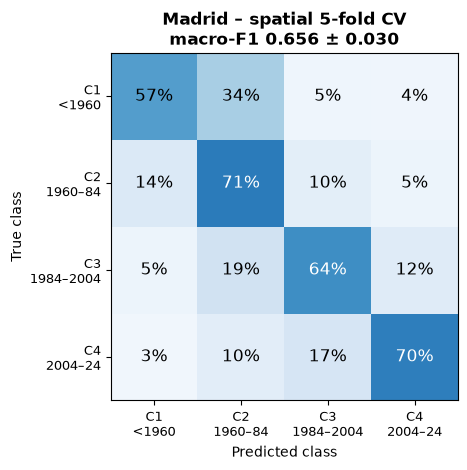

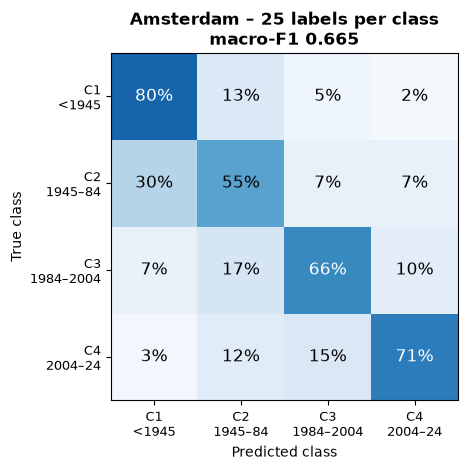

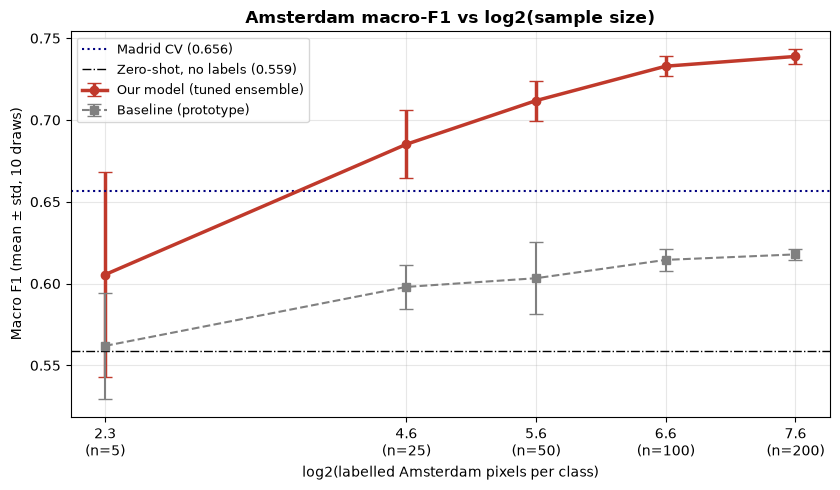

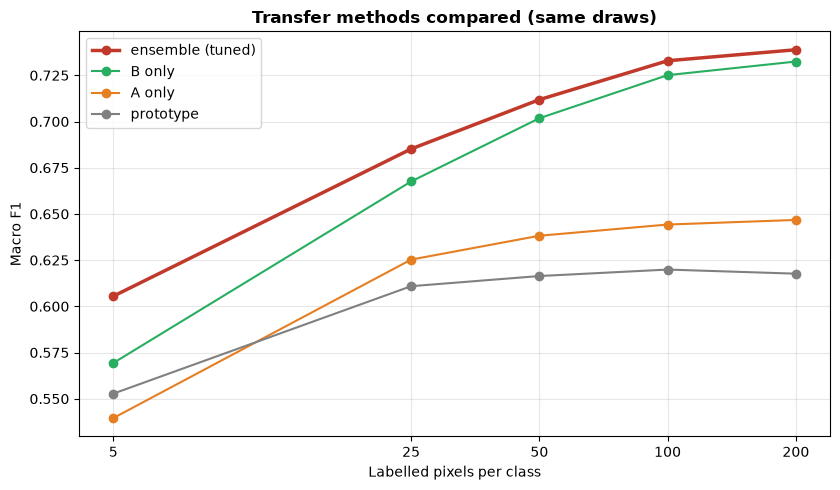

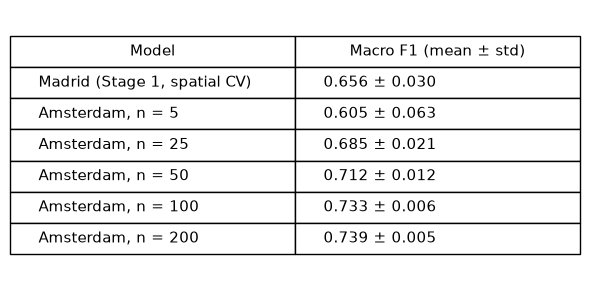


=========== NUMBERS FOR THE SLIDES ===========
Features: 277 total -> neighbourhood (new): 62, Notebook 3 (org_): 58, decade means: 44, change-point: 35, level (mean/std/median): 33, early vs late: 33, trend: 11, coverage: 1
Madrid: macro-F1 0.656 ± 0.030 | accuracy 66.5% | 5-fold spatial CV (1.5 km blocks)
Amsterdam zero-shot macro-F1: 0.559
Amsterdam n=  5: macro-F1 0.605 ± 0.063   (baseline 0.562)
Amsterdam n= 25: macro-F1 0.685 ± 0.021   (baseline 0.598)
Amsterdam n= 50: macro-F1 0.712 ± 0.012   (baseline 0.603)
Amsterdam n=100: macro-F1 0.733 ± 0.006   (baseline 0.614)
Amsterdam n=200: macro-F1 0.739 ± 0.005   (baseline 0.618)
Amsterdam n=25 accuracy (one draw): 66.9%
Average over n: 0.695  (baseline 0.599)
Tuned n=5: A=0.4, B=0.6, prototype=0, C=0.02, smoothing=True
Tuned n=25: A=0.4, B=0.6, prototype=0, C=0.05, smoothing=True
Tuned n=50: A=0.4, B=0.6, prototype=0, C=0.02, smoothing=True
Tuned n=100: A=0, B=1.0, prototype=0, C=0.02, smoothing=True
Tuned n=200: A=0, B=1.0, protot

In [18]:
# ═══ SLIDE ASSETS: images + numbers for the presentation ═══
from sklearn.metrics import accuracy_score
S = OUT_DIR / 'slides'; S.mkdir(exist_ok=True)
LAB_MAD = ['C1\n<1960', 'C2\n1960–84', 'C3\n1984–2004', 'C4\n2004–24']
LAB_AMS = ['C1\n<1945', 'C2\n1945–84', 'C3\n1984–2004', 'C4\n2004–24']

def save_cm(cmat, title, path, labels):
    fig, ax = plt.subplots(figsize=(5.4, 4.8))
    ax.imshow(cmat, cmap='Blues', vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{cmat[i, j]:.0%}', ha='center', va='center', fontsize=12,
                    color='white' if cmat[i, j] > 0.6 else 'black')
    ax.set_xticks(range(4), labels, fontsize=9); ax.set_yticks(range(4), labels, fontsize=9)
    ax.set_xlabel('Predicted class'); ax.set_ylabel('True class'); ax.set_title(title, fontweight='bold')
    plt.tight_layout(); plt.savefig(path, dpi=200); plt.show()

# 1) Madrid confusion matrix (slide 2)
acc_mad = accuracy_score(y_mad, oof_pred)
save_cm(cm, f'Madrid – spatial {N_FOLDS}-fold CV\nmacro-F1 {MAD_MEAN:.3f} ± {MAD_STD:.3f}', S / 'madrid_confusion.png', LAB_MAD)

# 2) Amsterdam confusion matrix, 25 labels per class (slide 3/4)
Xa = F_ams.loc[lab_ams, CANDIDATES[BEST]].to_numpy('float32')
L  = np.log(np.clip(stage1s[BEST].predict_proba(Xa), 1e-6, 1)); Z = StandardScaler().fit_transform(Xa)
s  = tuned[BEST][25]
sup = sample_support(y_ams, 25, np.random.default_rng(SEED + 1000 * 25)); q = np.setdiff1d(np.arange(len(y_ams)), sup)
pa, pb, pp = parts(sup, L, Z, s['C'])
pred25 = np.array(CLASSES)[combine(pa, pb, pp, s['wA'], s['wP'], s['smooth'])[q].argmax(1)]
cm25 = confusion_matrix(y_ams[q], pred25, labels=CLASSES, normalize='true')
save_cm(cm25, f'Amsterdam – 25 labels per class\nmacro-F1 {f1_score(y_ams[q], pred25, average="macro"):.3f}',
        S / 'amsterdam_confusion_n25.png', LAB_AMS)
acc25 = accuracy_score(y_ams[q], pred25)

# 3) Learning curve: F1 vs log2(n) with error bars (slide 4, REQUIRED)
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.errorbar(np.log2(final.index), final['mean'], yerr=final['std'], fmt='o-', color='#c0392b', lw=2.5,
            capsize=5, label='Our model (tuned ensemble)')
prev = pd.read_csv(IN_DIR / 'amsterdam_transfer_all_trials.csv')
b = prev[prev['method'] == 'prototype (NB4 baseline)'].groupby('n')['f1'].agg(['mean', 'std'])
ax.errorbar(np.log2(b.index), b['mean'], yerr=b['std'], fmt='s--', color='grey', capsize=5, label='Baseline (prototype)')
ax.axhline(MAD_MEAN, color='navy', ls=':', label=f'Madrid CV ({MAD_MEAN:.3f})')
ax.axhline(zeroshot[BEST], color='black', ls='-.', lw=1, label=f'Zero-shot, no labels ({zeroshot[BEST]:.3f})')
ax.set_xticks(np.log2(SHOTS), [f'{np.log2(n):.1f}\n(n={n})' for n in SHOTS])
ax.set_xlabel('log2(labelled Amsterdam pixels per class)'); ax.set_ylabel('Macro F1 (mean ± std, 10 draws)')
ax.set_title('Amsterdam macro-F1 vs log2(sample size)', fontweight='bold'); ax.grid(alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(S / 'learning_curve.png', dpi=200); plt.show()

# 4) Which transfer part works (slide 3 / 5)
fig, ax = plt.subplots(figsize=(8.5, 5))
for meth, col in [('ensemble (tuned)', '#c0392b'), ('B only', '#27ae60'), ('A only', '#e67e22'), ('prototype', 'grey')]:
    m = transfer[(transfer['features'] == BEST) & (transfer['method'] == meth)].groupby('n')['f1'].mean()
    ax.plot(np.log2(m.index), m.values, 'o-', color=col, lw=2.5 if 'ensemble' in meth else 1.5, label=meth)
ax.set_xticks(np.log2(SHOTS), [str(n) for n in SHOTS]); ax.set_xlabel('Labelled pixels per class')
ax.set_ylabel('Macro F1'); ax.set_title('Transfer methods compared (same draws)', fontweight='bold')
ax.grid(alpha=0.3); ax.legend(); plt.tight_layout(); plt.savefig(S / 'methods_comparison.png', dpi=200); plt.show()

# 5) Results table as an image (slide 4)
tbl = [['Madrid (Stage 1, spatial CV)', f'{MAD_MEAN:.3f} ± {MAD_STD:.3f}']] + \
      [[f'Amsterdam, n = {n}', f'{r["mean"]:.3f} ± {r["std"]:.3f}'] for n, r in final.iterrows()]
fig, ax = plt.subplots(figsize=(6, 3)); ax.axis('off')
t = ax.table(cellText=tbl, colLabels=['Model', 'Macro F1 (mean ± std)'], loc='center', cellLoc='left')
t.auto_set_font_size(False); t.set_fontsize(11); t.scale(1, 1.6)
plt.tight_layout(); plt.savefig(S / 'results_table.png', dpi=200, bbox_inches='tight'); plt.show()

# 6) Numbers to copy into the slides
grp = pd.Series([feature_group(c) for c in CANDIDATES[BEST]]).value_counts()
print('\n=========== NUMBERS FOR THE SLIDES ===========')
print(f'Features: {len(CANDIDATES[BEST])} total ->', ', '.join(f'{k}: {v}' for k, v in grp.items()))
print(f'Madrid: macro-F1 {MAD_MEAN:.3f} ± {MAD_STD:.3f} | accuracy {acc_mad:.1%} | {N_FOLDS}-fold spatial CV (1.5 km blocks)')
print(f'Amsterdam zero-shot macro-F1: {zeroshot[BEST]:.3f}')
for n, r in final.iterrows():
    print(f'Amsterdam n={n:3d}: macro-F1 {r["mean"]:.3f} ± {r["std"]:.3f}   (baseline {b.loc[n, "mean"]:.3f})')
print(f'Amsterdam n=25 accuracy (one draw): {acc25:.1%}')
print(f'Average over n: {final["mean"].mean():.3f}  (baseline {b["mean"].mean():.3f})')
for n, st in tuned[BEST].items():
    print(f'Tuned n={n}: A={st["wA"]}, B={1 - st["wA"] - st["wP"]:.1f}, prototype={st["wP"]}, C={st["C"]}, smoothing={st["smooth"]}')
print('\nImages saved in', S.resolve())

---
## Step 8 — What to send back / try next

Send a screenshot (or copy the text) of the **Step 5 summary table** and the **Step 7 printout**.

Next experiments, one at a time:
- `NB_RADII = [3, 10, 30]` (add a ~900 m neighbourhood) or `NB_TOP = 60`
- `SMOOTH_RADIUS = 4` or `SMOOTH_ALPHA = 0.7` (stronger smoothing)
- `DROP_GROUPS = ['year-to-year change', 'trend']`